# 07 — Eksperimen Lanjutan: Two-Stage Concept Pretraining, Ensemble & Adaptive Selector, serta Clinical-Taught Concept Learning

Notebook ini menambahkan 3 uji lanjutan (5-Fold CV konsisten dengan `01`–`06`, `stage7_only`, `patience=15`, `epochs=60`):
1. **Eksperimen 1 (Two-Stage Frozen Visual Concept -> Multimodal):** Melatih modul citra khusus 8 konsep sonografis di Stage 1, menyimpan fitur visualnya (`stage1_visual_features.npz`), membekukan bobot visual, lalu melatih penggabungan klinis + FiLM + hierarchical heads di Stage 2.
2. **Eksperimen 2 (Decision-Level Ensemble & Adaptive Selector):** Menggabungkan prediksi model klinis (`B1 Hier_RF_clean28`) dan model citra (`ImageOnly CrossAttn`, serta `PM3 End2End`) melalui *nested OOF late fusion*, *uncertainty-based adaptive selector* berbasis entropi, dan *meta-stacking*.
3. **Eksperimen 3 (Clinical-Taught Concept Stage 1 -> Hierarchical Stage 2):** Model guru klinis (8 Regresi Logistik pada 28 fitur klinis latih) mengajari cabang visual & FiLM mengenali 8 konsep terlebih dahulu di Stage 1 (*soft distillation + GT concepts*), baru kemudian di-*fine-tune* ke tugas *hierarchical 3-class* di Stage 2.


In [1]:
import copy, gc, json, sys, time
from dataclasses import asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from scipy.stats import binomtest, rankdata
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, f1_score, roc_auc_score

candidates = [Path.cwd(), *Path.cwd().parents]
PM3_DIR = next(
    (p if (p / "pm3_data.py").is_file() else p / "Proposed Model 3")
    for p in candidates
    if (p / "pm3_data.py").is_file() or (p / "Proposed Model 3" / "pm3_data.py").is_file()
)
ROOT_DIR = PM3_DIR.parent
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

from pm3_data import (
    CLASS_NAMES,
    CONCEPTS_PM3,
    ClinicalPipeline,
    PM3PatientBagDataset,
    USConfig,
    build_image_cache,
    collate_patients,
    images_by_patient,
    load_cohort,
    make_stratified_folds,
)
from pm3_model import ModelConfig, PM3Model
from pm3_train import (
    TrainConfig,
    bootstrap_ci,
    calibrate_thresholds_nested_oof,
    clip_gradients,
    combine_batch_loss,
    compute_metrics,
    evaluate,
    loss_terms,
    prepare_fold,
    save_json,
    set_seed,
    train_epoch,
    training_weights,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0), "| VRAM free/total (GiB):",
          [round(x / 1024**3, 2) for x in torch.cuda.mem_get_info()])
else:
    print("Device:", DEVICE)

RUNS_DIR = PM3_DIR / "runs"
OUT_DIR = RUNS_DIR / "07_advanced_two_stage_and_ensemble"
OUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_BACKBONE = "stage7_only"
SKIP_IF_DONE = True

cohort = load_cohort(ROOT_DIR / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT_DIR / "image_manifest_filtered.csv")
manifest["image_id"] = manifest["image_id"].astype(str)
manifest = manifest.loc[manifest["US_Number"].isin(cohort.index)].copy().reset_index(drop=True)
folds = make_stratified_folds(cohort, seed=1, n_splits=5)
bags_all = images_by_patient(manifest, bag_mode="all")
cache = build_image_cache(manifest, ROOT_DIR / "US_Pictures_clean", USConfig(), PM3_DIR / "cache")

print(f"Cohort: {len(cohort)} pasien | Folds: {len(folds)} | OUT_DIR: {OUT_DIR}")


def make_fold_datasets(fold: dict, modality: str, train_cfg: TrainConfig, seed_offset: int = 0):
    tr_df = cohort.loc[fold["train"]]
    va_df = cohort.loc[fold["val"]]
    pipe = ClinicalPipeline().fit(tr_df)
    include_img = modality in ("multimodal", "image_only")
    ds_tr = PM3PatientBagDataset(
        fold["train"], cohort, pipe, bags_all if include_img else None, cache if include_img else None,
        train=True, include_images=include_img, unrecorded_smoothing=train_cfg.unrecorded_smoothing,
    )
    ds_va = PM3PatientBagDataset(
        fold["val"], cohort, pipe, bags_all if include_img else None, cache if include_img else None,
        train=False, include_images=include_img, unrecorded_smoothing=train_cfg.unrecorded_smoothing,
    )
    weights = training_weights(
        ds_tr.labels, ds_tr.concepts_binary, ds_tr.concept_mask,
        comp_weight_mode=train_cfg.comp_weight_mode, severity_scope=train_cfg.severity_scope,
    )
    return pipe, ds_tr, ds_va, weights


@torch.inference_mode()
def eval_concept_stage(model: PM3Model, loader: DataLoader, weights: dict, device: torch.device, amp: bool):
    model.eval()
    pw_concepts = torch.tensor(weights["concept_pos_weight"], device=device, dtype=torch.float32)
    loss_sum, n_mask = 0.0, 0.0
    probs_list, y_list, mask_list = [], [], []
    for items in loader:
        lengths = [len(it["images"]) for it in items]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            all_imgs = torch.cat([it["images"] for it in items], dim=0).to(device, non_blocking=True)
            all_msks = torch.cat([it["pixel_masks"] for it in items], dim=0).to(device, non_blocking=True)
            all_h = model.encode_images_chunked(all_imgs, all_msks, allow_checkpoint=False, pad_to_microbatch=True)
            h_splits = torch.split(all_h, lengths, dim=0)
            for item, h_i in zip(items, h_splits):
                out = model.forward_from_embeddings(h_i, None) if model.cfg.modality == "image_only" else model.forward_from_embeddings(
                    h_i, item["tabular"].to(device, non_blocking=True)
                )
                c_log = out["concept_logits"].float()
                tgt = item["concepts_target"].to(device, dtype=torch.float32)
                msk = item["concept_mask"].to(device, dtype=torch.float32)
                loss_sum += float((F.binary_cross_entropy_with_logits(c_log, tgt, pos_weight=pw_concepts, reduction="none") * msk).sum())
                n_mask += float(msk.sum())
                probs_list.append(c_log.sigmoid().cpu().numpy())
                y_list.append(item["concepts_binary"].numpy())
                mask_list.append(item["concept_mask"].numpy())

    probs_arr = np.vstack(probs_list)
    y_arr = np.vstack(y_list)
    m_arr = np.vstack(mask_list)
    rows = []
    for k, cname in enumerate(CONCEPTS_PM3):
        valid = m_arr[:, k] > 0.5
        yk, pk = y_arr[valid, k], probs_arr[valid, k]
        auc_c = float(roc_auc_score(yk, pk)) if len(np.unique(yk)) == 2 else float("nan")
        f1_c = float(f1_score(yk, pk >= 0.5, zero_division=0)) if len(yk) else float("nan")
        rows.append({"concept": cname, "n_valid": int(valid.sum()), "n_positive": int(yk.sum()), "auroc": auc_c, "f1": f1_c})
    cdf = pd.DataFrame(rows)
    return float(loss_sum / max(n_mask, 1.0)), float(cdf["auroc"].mean()), float(cdf["f1"].mean()), cdf


@torch.inference_mode()
def extract_visual_features_npz(model: PM3Model, dataset: PM3PatientBagDataset, device: torch.device, amp: bool, save_path: Path):
    model.eval()
    loader = DataLoader(dataset, batch_size=16, shuffle=False, collate_fn=collate_patients)
    pids, labels, z_diag_l, z_comp_l, c_log_l, c_prob_l = [], [], [], [], [], []
    for items in loader:
        lengths = [len(it["images"]) for it in items]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            all_imgs = torch.cat([it["images"] for it in items], dim=0).to(device, non_blocking=True)
            all_msks = torch.cat([it["pixel_masks"] for it in items], dim=0).to(device, non_blocking=True)
            all_h = model.encode_images_chunked(all_imgs, all_msks, allow_checkpoint=False, pad_to_microbatch=True)
            h_splits = torch.split(all_h, lengths, dim=0)
            for item, h_i in zip(items, h_splits):
                za, _ = model.agg_diag(h_i, None)
                zb, _ = model.agg_comp(h_i, None)
                c_log = model.concept_head(0.5 * (za + zb)).float()
                pids.append(int(item["patient_id"]))
                labels.append(int(item["label"]))
                z_diag_l.append(za.float().cpu().numpy())
                z_comp_l.append(zb.float().cpu().numpy())
                c_log_l.append(c_log.cpu().numpy())
                c_prob_l.append(c_log.sigmoid().cpu().numpy())
    save_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        save_path,
        patient_id=np.asarray(pids, dtype=int),
        label=np.asarray(labels, dtype=int),
        z_raw_diag=np.vstack(z_diag_l).astype(np.float32),
        z_raw_comp=np.vstack(z_comp_l).astype(np.float32),
        concept_logits=np.vstack(c_log_l).astype(np.float32),
        concept_probs=np.vstack(c_prob_l).astype(np.float32),
    )


def train_stage2_hierarchical_fold(
    model: PM3Model,
    ds_tr: PM3PatientBagDataset,
    ds_va: PM3PatientBagDataset,
    weights: dict,
    model_cfg: ModelConfig,
    train_cfg: TrainConfig,
    fold_dir: Path,
    device: torch.device,
    fold_num: int,
    variant_label: str,
    freeze_keys: set = None,
):
    fold_dir.mkdir(parents=True, exist_ok=True)
    model_dir = fold_dir / "model"
    model_dir.mkdir(parents=True, exist_ok=True)
    seed = train_cfg.seed + fold_num
    set_seed(seed)

    freeze_keys = set(freeze_keys or ())
    if freeze_keys:
        for pname, p in model.named_parameters():
            if pname in freeze_keys:
                p.requires_grad_(False)

    backbone_frozen = (train_cfg.warmup_freeze_epochs > 0) or all(
        not p.requires_grad for p in model.encoder.trainable_stages.parameters()
    )
    if train_cfg.warmup_freeze_epochs > 0 and not freeze_keys:
        model.set_backbone_frozen(True)

    raw_groups = model.parameter_groups(
        backbone_lr=train_cfg.backbone_lr,
        attention_lr=train_cfg.attention_lr,
        head_lr=train_cfg.head_lr,
    )
    opt_groups = []
    for g in raw_groups:
        live_params = [p for p in g["params"] if p.requires_grad]
        if live_params:
            opt_groups.append({**g, "params": live_params})

    optimizer = torch.optim.AdamW(opt_groups)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=train_cfg.scheduler_t_max, eta_min=train_cfg.scheduler_eta_min
    )
    amp = train_cfg.amp_fp16 and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    train_loader = DataLoader(
        ds_tr, batch_size=train_cfg.batch_size, shuffle=True, num_workers=0,
        collate_fn=collate_patients, generator=torch.Generator().manual_seed(seed),
    )
    val_loader = DataLoader(
        ds_va, batch_size=train_cfg.batch_size, shuffle=False, num_workers=0, collate_fn=collate_patients,
    )

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"  [Stage2 {variant_label} | fold {fold_num}] trainable={n_trainable:,}/{n_total:,} params", flush=True)

    history, best, best_epoch = [], (-float("inf"), -float("inf")), 0
    no_improve, stopped_early = 0, False

    for epoch in range(1, train_cfg.epochs + 1):
        if (not freeze_keys) and train_cfg.warmup_freeze_epochs > 0 and epoch == train_cfg.warmup_freeze_epochs + 1:
            model.set_backbone_frozen(False)
            backbone_frozen = False

        t0 = time.perf_counter()
        used_lrs = {g["name"]: float(g["lr"]) for g in optimizer.param_groups}
        tr = train_epoch(model, train_loader, optimizer, scaler, weights, device, model_cfg, train_cfg)
        val, _, _, _ = evaluate(model, val_loader, weights, device, model_cfg, train_cfg, collect_attention=False)
        elapsed = time.perf_counter() - t0

        auroc_score = val["primary_auroc"] if np.isfinite(val["primary_auroc"]) else 0.0
        score = (auroc_score, -val["loss_total"])
        if score > best:
            best, best_epoch = score, epoch
            no_improve = 0
            torch.save({"model_state": model.state_dict(), "model_config": asdict(model_cfg), "epoch": epoch}, model_dir / "best_model.pt")
        else:
            no_improve += 1

        cm = val["confusion_matrix"]
        row = {
            "epoch": epoch, "seconds": elapsed, "backbone_frozen": backbone_frozen,
            **{f"lr_{k}": v for k, v in used_lrs.items()},
            **{f"train_{k}": v for k, v in tr.items()},
            **{f"val_{k}": v for k, v in val.items() if np.isscalar(v)},
            **{f"val_cm_{i}_{j}": int(cm[i][j]) for i in range(3) for j in range(3)},
            "best_epoch": best_epoch, "no_improve": no_improve,
        }
        history.append(row)
        pd.DataFrame(history).to_csv(model_dir / "history.csv", index=False)

        if epoch == 1 or epoch == best_epoch or epoch % 5 == 0 or no_improve >= train_cfg.patience:
            print(
                f"    ep {epoch:02d}/{train_cfg.epochs} (best {best_epoch:02d}, pat {no_improve:02d}/{train_cfg.patience}, {elapsed:.1f}s) | "
                f"tr_loss={tr['loss_total']:.3f} tr_auc={tr['primary_auroc']:.4f} | "
                f"val_loss={val['loss_total']:.3f} val_auc={val['primary_auroc']:.4f} val_mf1={val['macro_f1']:.4f}",
                flush=True,
            )

        if epoch <= train_cfg.scheduler_t_max:
            scheduler.step()
        if no_improve >= train_cfg.patience and epoch > train_cfg.warmup_freeze_epochs:
            stopped_early = True
            break

    state = torch.load(model_dir / "best_model.pt", map_location=device, weights_only=False)
    model.load_state_dict(state["model_state"])
    metrics, preds, concepts, attn = evaluate(model, val_loader, weights, device, model_cfg, train_cfg, collect_attention=True)
    metrics["best_epoch"] = best_epoch
    metrics["epochs_completed"] = len(history)
    metrics["stopped_early"] = stopped_early
    metrics["n_trainable_params"] = int(n_trainable)

    preds["fold"] = fold_num
    preds.to_csv(model_dir / "val_predictions.csv", index=False)
    concepts.to_csv(model_dir / "concept_metrics.csv", index=False)
    attn.to_csv(model_dir / "attention_weights.csv", index=False)
    ci_df = bootstrap_ci(preds, model_cfg.task_mode, train_cfg.bootstrap_samples, seed)
    ci_df.to_csv(model_dir / "ci95.csv", index=False)
    save_json(model_dir / "val_metrics.json", metrics)

    del state, optimizer, scheduler, scaler, train_loader, val_loader
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics, preds, concepts


def finalize_5fold_oof(oof_frames, fold_metrics_list, concept_frames, out_dir: Path, task_mode: str = "hierarchical", n_boot: int = 2000):
    out_dir.mkdir(parents=True, exist_ok=True)
    oof = pd.concat(oof_frames, ignore_index=True).sort_values(["fold", "patient_id"]).reset_index(drop=True)
    oof, oof_cal = calibrate_thresholds_nested_oof(oof, task_mode)
    probs = oof[["p_0", "p_1", "p_2"]].to_numpy()
    oof_fixed = compute_metrics(oof["label"].to_numpy(), probs, oof["pred"].to_numpy(), task_mode)
    ci_cal = bootstrap_ci(oof, task_mode, n_boot, seed=1, pred_col="pred_calibrated")

    fold_df = pd.DataFrame(fold_metrics_list)
    oof.to_csv(out_dir / "oof_predictions.csv", index=False)
    fold_df.to_csv(out_dir / "fold_metrics.csv", index=False)
    ci_cal.to_csv(out_dir / "oof_ci95.csv", index=False)
    save_json(out_dir / "oof_metrics_fixed.json", oof_fixed)
    save_json(out_dir / "oof_metrics_calibrated.json", oof_cal)
    if concept_frames:
        c_all = pd.concat(concept_frames, ignore_index=True)
        c_sum = c_all.groupby("concept", as_index=False).agg(
            n_valid=("n_valid", "sum"), n_positive=("n_positive", "sum"), auroc=("auroc", "mean"), f1=("f1", "mean")
        )
        c_sum.to_csv(out_dir / "concept_summary.csv", index=False)
    return oof_fixed, oof_cal, fold_df, oof


GPU: NVIDIA GeForce RTX 3060 Laptop GPU | VRAM free/total (GiB): [5.0, 6.0]
Preprocessing/cache PM3: 250/1741
Preprocessing/cache PM3: 500/1741
Preprocessing/cache PM3: 750/1741
Preprocessing/cache PM3: 1000/1741
Preprocessing/cache PM3: 1250/1741
Preprocessing/cache PM3: 1500/1741
Cohort: 578 pasien | Folds: 5 | OUT_DIR: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\07_advanced_two_stage_and_ensemble


In [2]:
# ==================== EKSPERIMEN 2: DECISION-LEVEL ENSEMBLE & ADAPTIVE SELECTOR ====================
exp2_dir = OUT_DIR / "exp2_ensemble"
exp2_dir.mkdir(parents=True, exist_ok=True)

# 1. Muat / rekonstruksi B1 Hier_RF_clean28 (patient-aligned OOF)
b1_rf_path = RUNS_DIR / "06_q1_statistical_analysis" / "b1_hier_rf_oof_predictions.csv"
if b1_rf_path.exists():
    rf_oof = pd.read_csv(b1_rf_path).sort_values("patient_id").reset_index(drop=True)
else:
    rows_rf = []
    for f in folds:
        tr_df, va_df = cohort.loc[f["train"]], cohort.loc[f["val"]]
        pipe = ClinicalPipeline().fit(tr_df)
        X_tr, y_tr = pipe.transform(tr_df), tr_df["label"].to_numpy(int)
        X_va, y_va = pipe.transform(va_df), va_df["label"].to_numpy(int)
        c_d = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42).fit(X_tr, (y_tr > 0).astype(int))
        m_app = y_tr > 0
        c_c = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42).fit(X_tr[m_app], (y_tr[m_app] == 2).astype(int))
        pd_, qc_ = c_d.predict_proba(X_va)[:, 1], c_c.predict_proba(X_va)[:, 1]
        for pid, yt, p, q in zip(va_df.index.to_numpy(int), y_va, pd_, qc_):
            rows_rf.append({
                "patient_id": int(pid), "fold": f["fold"], "label": int(yt),
                "p_diag": float(p), "q_comp": float(q),
                "p_0": float(1.0 - p), "p_1": float(p * (1.0 - q)), "p_2": float(p * q),
                "pred": int(0 if p < 0.5 else (1 if q < 0.5 else 2)),
            })
    rf_oof, _ = calibrate_thresholds_nested_oof(pd.DataFrame(rows_rf), "hierarchical")
    rf_oof = rf_oof.sort_values("patient_id").reset_index(drop=True)

img_oof = pd.read_csv(RUNS_DIR / "02_b2_image_only_hierarchical_cross_attn" / "oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)
pm3_oof = pd.read_csv(RUNS_DIR / f"02_backbone_{BEST_BACKBONE}" / "oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)

assert np.array_equal(rf_oof["patient_id"].to_numpy(), img_oof["patient_id"].to_numpy())
assert np.array_equal(rf_oof["patient_id"].to_numpy(), pm3_oof["patient_id"].to_numpy())

def _hier_probs(p_d, q_c):
    return np.column_stack([1.0 - p_d, p_d * (1.0 - q_c), p_d * q_c])

def _entropy3(probs):
    p = np.clip(probs, 1e-7, 1.0)
    return -(p * np.log(p)).sum(axis=1) / np.log(3.0)

def eval_save_oof(tag: str, oof_df: pd.DataFrame, extra: dict = None):
    d_sub = exp2_dir / tag
    d_sub.mkdir(parents=True, exist_ok=True)
    oof_cal, m_cal = calibrate_thresholds_nested_oof(oof_df.copy(), "hierarchical")
    probs = oof_cal[["p_0", "p_1", "p_2"]].to_numpy()
    m_fix = compute_metrics(oof_cal["label"].to_numpy(), probs, oof_cal["pred"].to_numpy(), "hierarchical")
    oof_cal.to_csv(d_sub / "oof_predictions.csv", index=False)
    save_json(d_sub / "oof_metrics_calibrated.json", m_cal)
    save_json(d_sub / "oof_metrics_fixed.json", m_fix)
    row = {
        "method": tag,
        "accuracy": m_cal["accuracy"],
        "macro_f1": m_cal["macro_f1"],
        "multiclass_auroc": m_cal["multiclass_auroc"],
        "macro_aupr": m_cal["macro_aupr"],
        "complication_recall": m_cal["complication_recall"],
        "macro_f1_fixed05": m_fix["macro_f1"],
    }
    if extra:
        row.update(extra)
    return row, oof_cal

def run_nested_late_fusion(tag: str, df_a: pd.DataFrame, df_b: pd.DataFrame):
    grid = np.round(np.arange(0.0, 1.01, 0.05), 2)
    merged = df_a.merge(df_b, on=["patient_id", "fold", "label"], suffixes=("_a", "_b"))
    oof_out = []
    alphas = []
    for fk in sorted(merged["fold"].unique()):
        tr = merged["fold"] != fk
        va = merged["fold"] == fk
        y_tr = merged.loc[tr, "label"].to_numpy(int)
        pda, qca = merged.loc[tr, "p_diag_a"].to_numpy(), merged.loc[tr, "q_comp_a"].to_numpy()
        pdb, qcb = merged.loc[tr, "p_diag_b"].to_numpy(), merged.loc[tr, "q_comp_b"].to_numpy()

        best_auc, best_pair = -1.0, (0.5, 0.5)
        for ad in grid:
            pd_mix = ad * pda + (1.0 - ad) * pdb
            for ac in grid:
                qc_mix = ac * qca + (1.0 - ac) * qcb
                auc = float(roc_auc_score(y_tr, _hier_probs(pd_mix, qc_mix), labels=[0, 1, 2], multi_class="ovr", average="macro"))
                if auc > best_auc:
                    best_auc = auc
                    best_pair = (float(ad), float(ac))
        ad_star, ac_star = best_pair
        alphas.append(best_pair)
        pd_v = ad_star * merged.loc[va, "p_diag_a"].to_numpy() + (1.0 - ad_star) * merged.loc[va, "p_diag_b"].to_numpy()
        qc_v = ac_star * merged.loc[va, "q_comp_a"].to_numpy() + (1.0 - ac_star) * merged.loc[va, "q_comp_b"].to_numpy()
        pr_v = _hier_probs(pd_v, qc_v)
        for pid, yt, p_d, q_c, pvec in zip(merged.loc[va, "patient_id"], merged.loc[va, "label"], pd_v, qc_v, pr_v):
            oof_out.append({
                "patient_id": int(pid), "fold": int(fk), "label": int(yt),
                "p_diag": float(p_d), "q_comp": float(q_c),
                "p_0": float(pvec[0]), "p_1": float(pvec[1]), "p_2": float(pvec[2]),
                "pred": int(0 if p_d < 0.5 else (1 if q_c < 0.5 else 2)),
            })
    mean_ad = float(np.mean([x[0] for x in alphas]))
    mean_ac = float(np.mean([x[1] for x in alphas]))
    return eval_save_oof(tag, pd.DataFrame(oof_out), {"note": f"mean_alpha_diag={mean_ad:.2f}, alpha_comp={mean_ac:.2f}"})

exp2_rows = []
# Baseline referensi langsung
r_rf, _ = eval_save_oof("Ref_B1_Hier_RF_clean28", rf_oof[["patient_id","fold","label","p_diag","q_comp","p_0","p_1","p_2","pred"]])
r_im, _ = eval_save_oof("Ref_ImageOnly_CrossAttn", img_oof[["patient_id","fold","label","p_diag","q_comp","p_0","p_1","p_2","pred"]])
r_pm, _ = eval_save_oof("Ref_PM3_End2End_FiLM", pm3_oof[["patient_id","fold","label","p_diag","q_comp","p_0","p_1","p_2","pred"]])

# 2A: Nested OOF Late Fusion (B1 Hier_RF + ImageOnly CrossAttn)
r_2a, oof_2a = run_nested_late_fusion("Exp2A_LateFusion_RF_plus_ImageOnly", rf_oof, img_oof)
exp2_rows.append(r_2a)

# 2B: Nested OOF Uncertainty-Based Adaptive Selector (pilih Clinical vs Image berdasarkan entropy gap)
merged_ri = rf_oof.merge(img_oof, on=["patient_id", "fold", "label"], suffixes=("_rf", "_im"))
h_rf = _entropy3(merged_ri[["p_0_rf", "p_1_rf", "p_2_rf"]].to_numpy())
h_im = _entropy3(merged_ri[["p_0_im", "p_1_im", "p_2_im"]].to_numpy())
merged_ri["h_diff"] = h_rf - h_im  # positif berarti Clinical lebih ragu dibanding Image
delta_grid = np.round(np.arange(-0.30, 0.31, 0.03), 2)
oof_2b_list, img_routed_cnt = [], 0
for fk in sorted(merged_ri["fold"].unique()):
    tr, va = merged_ri["fold"] != fk, merged_ri["fold"] == fk
    y_tr = merged_ri.loc[tr, "label"].to_numpy(int)
    p_rf_tr = merged_ri.loc[tr, ["p_0_rf", "p_1_rf", "p_2_rf"]].to_numpy()
    p_im_tr = merged_ri.loc[tr, ["p_0_im", "p_1_im", "p_2_im"]].to_numpy()
    hd_tr = merged_ri.loc[tr, "h_diff"].to_numpy()
    best_auc, best_d = -1.0, 0.0
    for d_thr in delta_grid:
        use_im = (hd_tr > d_thr)[:, None]
        p_mix = np.where(use_im, p_im_tr, p_rf_tr)
        auc = float(roc_auc_score(y_tr, p_mix, labels=[0, 1, 2], multi_class="ovr", average="macro"))
        if auc > best_auc:
            best_auc, best_d = auc, float(d_thr)
    va_df = merged_ri.loc[va]
    use_im_va = va_df["h_diff"].to_numpy() > best_d
    img_routed_cnt += int(use_im_va.sum())
    for idx_r, (_, row) in enumerate(va_df.iterrows()):
        src = "im" if use_im_va[idx_r] else "rf"
        pd_v, qc_v = float(row[f"p_diag_{src}"]), float(row[f"q_comp_{src}"])
        p0, p1, p2 = float(row[f"p_0_{src}"]), float(row[f"p_1_{src}"]), float(row[f"p_2_{src}"])
        oof_2b_list.append({
            "patient_id": int(row["patient_id"]), "fold": int(fk), "label": int(row["label"]),
            "p_diag": pd_v, "q_comp": qc_v, "p_0": p0, "p_1": p1, "p_2": p2,
            "pred": int(0 if pd_v < 0.5 else (1 if qc_v < 0.5 else 2)),
            "selected_modality": "image" if use_im_va[idx_r] else "clinical",
        })
r_2b, oof_2b = eval_save_oof("Exp2B_UncertaintySelector_RF_vs_Image", pd.DataFrame(oof_2b_list), {"note": f"routed_to_image={img_routed_cnt}/{len(merged_ri)} ({img_routed_cnt/len(merged_ri)*100:.1f}%)"})
exp2_rows.append(r_2b)

# 2C: Meta-Stacking LogisticRegression pada probabilitas & uncertainty Clinical + Image (tanpa bag_len!)
X_meta = np.column_stack([
    merged_ri[["p_0_rf", "p_1_rf", "p_2_rf", "p_0_im", "p_1_im", "p_2_im"]].to_numpy(),
    h_rf, h_im,
    merged_ri[["p_0_rf", "p_1_rf", "p_2_rf"]].max(axis=1).to_numpy(),
    merged_ri[["p_0_im", "p_1_im", "p_2_im"]].max(axis=1).to_numpy(),
])
oof_2c_list = []
for fk in sorted(merged_ri["fold"].unique()):
    tr, va = (merged_ri["fold"] != fk).to_numpy(), (merged_ri["fold"] == fk).to_numpy()
    meta_clf = LogisticRegression(max_iter=1000, C=0.5, class_weight="balanced", random_state=42).fit(
        X_meta[tr], merged_ri.loc[tr, "label"].to_numpy(int)
    )
    pr_v = meta_clf.predict_proba(X_meta[va])
    for (_, row), pvec in zip(merged_ri.loc[va].iterrows(), pr_v):
        p_d = float(1.0 - pvec[0])
        q_c = float(pvec[2] / max(p_d, 1e-6))
        oof_2c_list.append({
            "patient_id": int(row["patient_id"]), "fold": int(fk), "label": int(row["label"]),
            "p_diag": p_d, "q_comp": float(np.clip(q_c, 0.0, 1.0)),
            "p_0": float(pvec[0]), "p_1": float(pvec[1]), "p_2": float(pvec[2]),
            "pred": int(np.argmax(pvec)),
        })
d_2c = exp2_dir / "Exp2C_MetaStacking_RF_plus_ImageOnly"
d_2c.mkdir(parents=True, exist_ok=True)
df_2c = pd.DataFrame(oof_2c_list)
m_2c = compute_metrics(df_2c["label"].to_numpy(), df_2c[["p_0","p_1","p_2"]].to_numpy(), df_2c["pred"].to_numpy(), "softmax")
df_2c["pred_calibrated"] = df_2c["pred"]
df_2c.to_csv(d_2c / "oof_predictions.csv", index=False)
save_json(d_2c / "oof_metrics_calibrated.json", m_2c)
save_json(d_2c / "oof_metrics_fixed.json", m_2c)
exp2_rows.append({
    "method": "Exp2C_MetaStacking_RF_plus_ImageOnly",
    "accuracy": m_2c["accuracy"], "macro_f1": m_2c["macro_f1"], "multiclass_auroc": m_2c["multiclass_auroc"],
    "macro_aupr": m_2c["macro_aupr"], "complication_recall": m_2c["complication_recall"], "macro_f1_fixed05": m_2c["macro_f1"],
    "note": "LogReg stacking on probs + entropy (no bag_len)",
})

# 2D: Hybrid Late Fusion PM3_End2End + B1_Hier_RF
r_2d, oof_2d = run_nested_late_fusion("Exp2D_Hybrid_PM3_plus_RF", pm3_oof, rf_oof)
exp2_rows.append(r_2d)

df_exp2 = pd.DataFrame([r_rf, r_im, r_pm] + exp2_rows)
df_exp2.to_csv(OUT_DIR / "exp2_ensemble_summary.csv", index=False)
print("=== EKSPRERIMEN 2: ENSEMBLE & ADAPTIVE SELECTOR ===")
display(df_exp2.round(4))


=== EKSPRERIMEN 2: ENSEMBLE & ADAPTIVE SELECTOR ===


,method,accuracy,macro_f1,multiclass_auroc,macro_aupr,complication_recall,macro_f1_fixed05,note
0,Ref_B1_Hier_RF_clean28,0.6522,0.6414,0.7937,0.6390,0.6354,0.6210,NaN
1,Ref_ImageOnly_CrossAttn,0.5000,0.4745,0.7005,0.5173,0.4167,0.5110,NaN
2,Ref_PM3_End2End_FiLM,0.6384,0.6291,0.8009,0.6410,0.6042,0.6185,NaN
3,Exp2A_LateFusion_RF_plus_ImageOnly,0.6280,0.6242,0.8096,0.6539,0.7292,0.6280,"mean_alpha_diag=0.71, alpha_comp=0.68"
4,Exp2B_UncertaintySelector_RF_vs_Image,0.6401,0.6322,0.7676,0.5919,0.6458,0.6187,routed_to_image=97/578 (16.8%)
5,Exp2C_MetaStacking_RF_plus_ImageOnly,0.6280,0.6300,0.7994,0.6329,0.8021,0.6300,LogReg stacking on probs + entropy (no bag_len)
6,Exp2D_Hybrid_PM3_plus_RF,0.6263,0.6263,0.8130,0.6606,0.6667,0.6462,"mean_alpha_diag=0.46, alpha_comp=0.41"


In [3]:
# ==================== EKSPERIMEN 1: STAGE-1 CONCEPT PRETRAIN -> STAGE-2 FROZEN VISUAL MM ====================
exp1_dir = OUT_DIR / "exp1_concept_pretrain_frozen_mm"
exp1_dir.mkdir(parents=True, exist_ok=True)

STAGE1_EPOCHS = 35
STAGE1_PATIENCE = 12
STAGE2_CFG = TrainConfig(
    epochs=60, batch_size=16, patience=15, warmup_freeze_epochs=0, seed=1,
    w_concept=0.0, w_aux_img=0.0,  # visual branch & concept head dibekukan dari Stage 1
)
STAGE1_MCFG = ModelConfig(
    clinical_dim=28, num_concepts=8, modality="image_only", backbone_mode=BEST_BACKBONE,
    aggregator="cross_attn", fusion_mode="film", task_mode="hierarchical", use_concepts=True,
)
STAGE2_MCFG = ModelConfig(
    clinical_dim=28, num_concepts=8, modality="multimodal", backbone_mode=BEST_BACKBONE,
    aggregator="cross_attn", fusion_mode="film", task_mode="hierarchical", use_concepts=True,
)

exp1_fold_metrics, exp1_oofs, exp1_concepts = [], [], []
amp_flag = DEVICE.type == "cuda"

for f in folds:
    fk = f["fold"]
    fdir = exp1_dir / f"fold_{fk}"
    m_json = fdir / "model" / "val_metrics.json"
    p_csv = fdir / "model" / "val_predictions.csv"
    c_csv = fdir / "model" / "concept_metrics.csv"

    if SKIP_IF_DONE and m_json.exists() and p_csv.exists():
        print(f"[SKIP Exp1] fold {fk} sudah selesai — memuat hasil.")
        exp1_fold_metrics.append(json.loads(m_json.read_text(encoding="utf-8")))
        exp1_oofs.append(pd.read_csv(p_csv))
        if c_csv.exists():
            exp1_concepts.append(pd.read_csv(c_csv))
        continue

    tcfg_s1 = TrainConfig(epochs=STAGE1_EPOCHS, batch_size=16, patience=STAGE1_PATIENCE, warmup_freeze_epochs=3, seed=1)
    pipe, ds_tr, ds_va, weights = make_fold_datasets(f, "multimodal", tcfg_s1)
    ds_tr_eval = PM3PatientBagDataset(f["train"], cohort, pipe, bags_all, cache, train=False, include_images=True)

    # --- Stage 1: Pure Image-Only Concept Pretraining ---
    s1_ckpt = fdir / "stage1_concept_best.pt"
    s1_npz = fdir / "stage1_visual_features.npz"
    model_s1 = PM3Model(STAGE1_MCFG).to(DEVICE)

    if not (SKIP_IF_DONE and s1_ckpt.exists() and s1_npz.exists()):
        print(f"\n>>> [Exp1 Stage 1 | Fold {fk}] Pure Image-Only Concept Pretraining (max {STAGE1_EPOCHS} ep)...", flush=True)
        set_seed(tcfg_s1.seed + fk)
        model_s1.set_backbone_frozen(True)
        opt1 = torch.optim.AdamW(model_s1.parameter_groups(backbone_lr=2e-5, attention_lr=3e-4, head_lr=4e-4))
        sch1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt1, T_max=STAGE1_EPOCHS, eta_min=1e-6)
        scaler1 = torch.amp.GradScaler("cuda", enabled=amp_flag)
        pw_c = torch.tensor(weights["concept_pos_weight"], device=DEVICE, dtype=torch.float32)

        tr_loader1 = DataLoader(ds_tr, batch_size=16, shuffle=True, num_workers=0, collate_fn=collate_patients,
                                generator=torch.Generator().manual_seed(tcfg_s1.seed + fk))
        va_loader1 = DataLoader(ds_va, batch_size=16, shuffle=False, num_workers=0, collate_fn=collate_patients)

        best_s1, best_ep1, no_imp1, s1_hist = (-float("inf"), -float("inf")), 0, 0, []
        for ep in range(1, STAGE1_EPOCHS + 1):
            if ep == 4:
                model_s1.set_backbone_frozen(False)
            model_s1.train()
            tr_loss_acc, tr_m_acc = 0.0, 0.0
            for items in tr_loader1:
                opt1.zero_grad(set_to_none=True)
                lengths = [len(it["images"]) for it in items]
                n_con = max(sum(float(it["concept_mask"].sum()) for it in items), 1.0)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_flag):
                    all_imgs = torch.cat([it["images"] for it in items], dim=0).to(DEVICE, non_blocking=True)
                    all_msks = torch.cat([it["pixel_masks"] for it in items], dim=0).to(DEVICE, non_blocking=True)
                    all_h = model_s1.encode_images_chunked(all_imgs, all_msks, pad_to_microbatch=True)
                    h_splits = torch.split(all_h, lengths, dim=0)
                    bloss = torch.tensor(0.0, device=DEVICE, dtype=torch.float32)
                    for it, hi in zip(items, h_splits):
                        out = model_s1.forward_from_embeddings(hi, None)
                        tgt = it["concepts_target"].to(DEVICE, dtype=torch.float32)
                        msk = it["concept_mask"].to(DEVICE, dtype=torch.float32)
                        bloss = bloss + (F.binary_cross_entropy_with_logits(out["concept_logits"].float(), tgt, pos_weight=pw_c, reduction="none") * msk).sum() / n_con
                tr_loss_acc += float(bloss.detach()) * n_con
                tr_m_acc += n_con
                scaler1.scale(bloss).backward()
                scaler1.unscale_(opt1)
                if all(torch.isfinite(p.grad).all() for p in model_s1.parameters() if p.grad is not None):
                    clip_gradients(model_s1)
                scaler1.step(opt1)
                scaler1.update()

            va_loss, va_cauc, va_cf1, va_cdf = eval_concept_stage(model_s1, va_loader1, weights, DEVICE, amp_flag)
            sc1 = (va_cauc if np.isfinite(va_cauc) else 0.0, -va_loss)
            if sc1 > best_s1:
                best_s1, best_ep1, no_imp1 = sc1, ep, 0
                fdir.mkdir(parents=True, exist_ok=True)
                torch.save({"model_state": model_s1.state_dict(), "best_epoch": ep, "val_concept_auc": va_cauc}, s1_ckpt)
            else:
                no_imp1 += 1
            s1_hist.append({"epoch": ep, "tr_concept_loss": tr_loss_acc / max(tr_m_acc, 1.0), "val_concept_loss": va_loss, "val_concept_auc": va_cauc, "val_concept_f1": va_cf1})
            if ep == 1 or ep == best_ep1 or ep % 5 == 0 or no_imp1 >= STAGE1_PATIENCE:
                print(f"    [S1 ep {ep:02d}] best={best_ep1:02d} pat={no_imp1:02d}/{STAGE1_PATIENCE} | val_concept_loss={va_loss:.4f} | val_concept_AUC={va_cauc:.4f}", flush=True)
            sch1.step()
            if no_imp1 >= STAGE1_PATIENCE and ep > 3:
                break

        pd.DataFrame(s1_hist).to_csv(fdir / "stage1_history.csv", index=False)
        st1 = torch.load(s1_ckpt, map_location=DEVICE, weights_only=False)
        model_s1.load_state_dict(st1["model_state"])
        _, _, _, s1_cdf = eval_concept_stage(model_s1, va_loader1, weights, DEVICE, amp_flag)
        s1_cdf.to_csv(fdir / "stage1_concept_metrics.csv", index=False)
        # Simpan fitur visual lengkap (train + val)
        extract_visual_features_npz(model_s1, ds_tr_eval, DEVICE, amp_flag, fdir / "stage1_visual_features_train.npz")
        extract_visual_features_npz(model_s1, ds_va, DEVICE, amp_flag, s1_npz)
        del opt1, sch1, scaler1, tr_loader1, va_loader1

    # --- Stage 2: Muat Bobot Visual Concept & Bekukan Total di Multimodal ---
    st1 = torch.load(s1_ckpt, map_location=DEVICE, weights_only=False)
    s1_state = st1["model_state"]
    model_s2 = PM3Model(STAGE2_MCFG).to(DEVICE)
    s2_dict = model_s2.state_dict()
    matched = {k: v for k, v in s1_state.items() if k in s2_dict and s2_dict[k].shape == v.shape and not k.startswith("head_") and not k.startswith("aux_")}
    model_s2.load_state_dict(matched, strict=False)
    freeze_names = set(matched.keys())
    print(f"  [Exp1 Fold {fk}] Stage1->Stage2 loaded & FROZE {len(freeze_names)} tensor visual/concept.")

    m, p, c = train_stage2_hierarchical_fold(
        model_s2, ds_tr, ds_va, weights, STAGE2_MCFG, STAGE2_CFG, fdir, DEVICE, fk, "Exp1_FrozenVis", freeze_keys=freeze_names
    )
    exp1_fold_metrics.append(m)
    exp1_oofs.append(p)
    exp1_concepts.append(c)
    del model_s1, model_s2
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

exp1_fix, exp1_cal, exp1_fdf, exp1_oof = finalize_5fold_oof(exp1_oofs, exp1_fold_metrics, exp1_concepts, exp1_dir)
print(f"\n[DONE Exp1] Calibrated OOF -> Acc={exp1_cal['accuracy']:.4f} | MacroF1={exp1_cal['macro_f1']:.4f} | AUROC={exp1_cal['multiclass_auroc']:.4f} | CompRec={exp1_cal['complication_recall']:.4f}")



>>> [Exp1 Stage 1 | Fold 1] Pure Image-Only Concept Pretraining (max 35 ep)...
    [S1 ep 01] best=01 pat=00/12 | val_concept_loss=0.8693 | val_concept_AUC=0.5651
    [S1 ep 02] best=02 pat=00/12 | val_concept_loss=0.8506 | val_concept_AUC=0.6199
    [S1 ep 03] best=03 pat=00/12 | val_concept_loss=0.8771 | val_concept_AUC=0.6462
    [S1 ep 05] best=05 pat=00/12 | val_concept_loss=0.8493 | val_concept_AUC=0.6581
    [S1 ep 06] best=06 pat=00/12 | val_concept_loss=0.8367 | val_concept_AUC=0.6594
    [S1 ep 07] best=07 pat=00/12 | val_concept_loss=0.8424 | val_concept_AUC=0.6638
    [S1 ep 08] best=08 pat=00/12 | val_concept_loss=0.8261 | val_concept_AUC=0.6671
    [S1 ep 10] best=08 pat=02/12 | val_concept_loss=0.8710 | val_concept_AUC=0.6609
    [S1 ep 15] best=08 pat=07/12 | val_concept_loss=0.8656 | val_concept_AUC=0.6587
    [S1 ep 20] best=08 pat=12/12 | val_concept_loss=0.8722 | val_concept_AUC=0.6602
  [Exp1 Fold 1] Stage1->Stage2 loaded & FROZE 396 tensor visual/concept.
  [Stag

In [4]:
# ==================== EKSPERIMEN 3: CLINICAL-TAUGHT CONCEPT STAGE 1 -> HIERARCHICAL STAGE 2 ====================
exp3_dir = OUT_DIR / "exp3_clin_taught_concept_to_hier"
exp3_dir.mkdir(parents=True, exist_ok=True)

STAGE1_EPOCHS_3 = 35
STAGE1_PATIENCE_3 = 12
STAGE2_CFG_3 = TrainConfig(epochs=60, batch_size=16, patience=15, warmup_freeze_epochs=3, seed=1)
MM_MCFG_3 = ModelConfig(
    clinical_dim=28, num_concepts=8, modality="multimodal", backbone_mode=BEST_BACKBONE,
    aggregator="cross_attn", fusion_mode="film", task_mode="hierarchical", use_concepts=True,
)

exp3_fold_metrics, exp3_oofs, exp3_concepts = [], [], []
amp_flag = DEVICE.type == "cuda"

for f in folds:
    fk = f["fold"]
    fdir = exp3_dir / f"fold_{fk}"
    m_json = fdir / "model" / "val_metrics.json"
    p_csv = fdir / "model" / "val_predictions.csv"
    c_csv = fdir / "model" / "concept_metrics.csv"

    if SKIP_IF_DONE and m_json.exists() and p_csv.exists():
        print(f"[SKIP Exp3] fold {fk} sudah selesai — memuat hasil.")
        exp3_fold_metrics.append(json.loads(m_json.read_text(encoding="utf-8")))
        exp3_oofs.append(pd.read_csv(p_csv))
        if c_csv.exists():
            exp3_concepts.append(pd.read_csv(c_csv))
        continue

    tcfg_s1 = TrainConfig(epochs=STAGE1_EPOCHS_3, batch_size=16, patience=STAGE1_PATIENCE_3, warmup_freeze_epochs=3, seed=1)
    pipe, ds_tr, ds_va, weights = make_fold_datasets(f, "multimodal", tcfg_s1)

    # --- Stage 1A: Latih 8 Clinical Teacher (LogReg pada 28 fitur klinis TRAIN saja) ---
    X_tr_clin = ds_tr.tabular
    y_c_bin = ds_tr.concepts_binary
    m_c_tr = ds_tr.concept_mask
    teacher_probs = np.full((len(ds_tr), len(CONCEPTS_PM3)), 0.5, dtype=np.float32)
    for c_i in range(len(CONCEPTS_PM3)):
        valid = m_c_tr[:, c_i] > 0.5
        yc = y_c_bin[valid, c_i].astype(int)
        if valid.sum() >= 10 and len(np.unique(yc)) == 2:
            t_clf = LogisticRegression(max_iter=1000, C=0.5, class_weight="balanced", random_state=42).fit(X_tr_clin[valid], yc)
            teacher_probs[:, c_i] = t_clf.predict_proba(X_tr_clin)[:, 1].astype(np.float32)
    teacher_map = {int(pid): torch.from_numpy(teacher_probs[idx]) for idx, pid in enumerate(ds_tr.pids)}

    # --- Stage 1B: Modul Klinis Mengajari Modul Image Concept (GT + Clinical Soft Teacher + FiLM Concept Head) ---
    s1_ckpt = fdir / "stage1_clin_taught_best.pt"
    model_s1 = PM3Model(MM_MCFG_3).to(DEVICE)
    film_concept_head = nn.Linear(64, 8).to(DEVICE)

    if not (SKIP_IF_DONE and s1_ckpt.exists()):
        print(f"\n>>> [Exp3 Stage 1 | Fold {fk}] Clinical-Taught Concept Pretraining (max {STAGE1_EPOCHS_3} ep)...", flush=True)
        set_seed(tcfg_s1.seed + fk)
        model_s1.set_backbone_frozen(True)
        params_s1 = model_s1.parameter_groups(backbone_lr=2e-5, attention_lr=2e-4, head_lr=4e-4)
        params_s1.append({"name": "film_concept_head", "params": list(film_concept_head.parameters()), "lr": 4e-4, "weight_decay": 1e-4})
        opt1 = torch.optim.AdamW(params_s1)
        sch1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt1, T_max=STAGE1_EPOCHS_3, eta_min=1e-6)
        scaler1 = torch.amp.GradScaler("cuda", enabled=amp_flag)
        pw_c = torch.tensor(weights["concept_pos_weight"], device=DEVICE, dtype=torch.float32)

        tr_loader1 = DataLoader(ds_tr, batch_size=16, shuffle=True, num_workers=0, collate_fn=collate_patients,
                                generator=torch.Generator().manual_seed(tcfg_s1.seed + fk))
        va_loader1 = DataLoader(ds_va, batch_size=16, shuffle=False, num_workers=0, collate_fn=collate_patients)

        best_s1, best_ep1, no_imp1, s1_hist = (-float("inf"), -float("inf")), 0, 0, []
        for ep in range(1, STAGE1_EPOCHS_3 + 1):
            if ep == 4:
                model_s1.set_backbone_frozen(False)
            model_s1.train(); film_concept_head.train()
            tr_loss_acc, tr_m_acc = 0.0, 0.0
            for items in tr_loader1:
                opt1.zero_grad(set_to_none=True)
                n_b = len(items)
                lengths = [len(it["images"]) for it in items]
                n_con = max(sum(float(it["concept_mask"].sum()) for it in items), 1.0)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_flag):
                    all_imgs = torch.cat([it["images"] for it in items], dim=0).to(DEVICE, non_blocking=True)
                    all_msks = torch.cat([it["pixel_masks"] for it in items], dim=0).to(DEVICE, non_blocking=True)
                    all_h = model_s1.encode_images_chunked(all_imgs, all_msks, pad_to_microbatch=True)
                    h_splits = torch.split(all_h, lengths, dim=0)
                    bloss = torch.tensor(0.0, device=DEVICE, dtype=torch.float32)
                    for it, hi in zip(items, h_splits):
                        tab = it["tabular"].to(DEVICE, non_blocking=True)
                        e_clin = model_s1.clinical_mlp(tab.float())
                        za_raw, _ = model_s1.agg_diag(hi, None)
                        zb_raw, _ = model_s1.agg_comp(hi, None)
                        vis_clog = model_s1.concept_head(0.5 * (za_raw + zb_raw)).float()

                        h_main, _, _ = model_s1.inst_film(hi, e_clin)
                        za, _ = model_s1.agg_diag(h_main, e_clin)
                        zb, _ = model_s1.agg_comp(h_main, e_clin)
                        fa, _ = model_s1._fuse_branch(za, e_clin, "a")
                        fb, _ = model_s1._fuse_branch(zb, e_clin, "b")
                        film_clog = film_concept_head(0.5 * (fa + fb)).float()

                        tgt = it["concepts_target"].to(DEVICE, dtype=torch.float32)
                        msk = it["concept_mask"].to(DEVICE, dtype=torch.float32)
                        t_prob = teacher_map[int(it["patient_id"])].to(DEVICE, dtype=torch.float32)

                        l_vis_gt = (F.binary_cross_entropy_with_logits(vis_clog, tgt, pos_weight=pw_c, reduction="none") * msk).sum() / n_con
                        l_distill = F.binary_cross_entropy_with_logits(vis_clog, t_prob, reduction="mean") / n_b
                        l_film_gt = (F.binary_cross_entropy_with_logits(film_clog, tgt, pos_weight=pw_c, reduction="none") * msk).sum() / n_con
                        bloss = bloss + l_vis_gt + 0.35 * l_distill + 0.35 * l_film_gt

                tr_loss_acc += float(bloss.detach()) * n_b
                tr_m_acc += n_b
                scaler1.scale(bloss).backward()
                scaler1.unscale_(opt1)
                if all(torch.isfinite(p.grad).all() for p in model_s1.parameters() if p.grad is not None):
                    clip_gradients(model_s1)
                scaler1.step(opt1)
                scaler1.update()

            va_loss, va_cauc, va_cf1, _ = eval_concept_stage(model_s1, va_loader1, weights, DEVICE, amp_flag)
            sc1 = (va_cauc if np.isfinite(va_cauc) else 0.0, -va_loss)
            if sc1 > best_s1:
                best_s1, best_ep1, no_imp1 = sc1, ep, 0
                fdir.mkdir(parents=True, exist_ok=True)
                torch.save({"model_state": model_s1.state_dict(), "best_epoch": ep, "val_concept_auc": va_cauc}, s1_ckpt)
            else:
                no_imp1 += 1
            s1_hist.append({"epoch": ep, "tr_stage1_loss": tr_loss_acc / max(tr_m_acc, 1.0), "val_vis_concept_loss": va_loss, "val_vis_concept_auc": va_cauc, "val_vis_concept_f1": va_cf1})
            if ep == 1 or ep == best_ep1 or ep % 5 == 0 or no_imp1 >= STAGE1_PATIENCE_3:
                print(f"    [S1 ep {ep:02d}] best={best_ep1:02d} pat={no_imp1:02d}/{STAGE1_PATIENCE_3} | val_vis_concept_AUC={va_cauc:.4f} | val_loss={va_loss:.4f}", flush=True)
            sch1.step()
            if no_imp1 >= STAGE1_PATIENCE_3 and ep > 3:
                break

        pd.DataFrame(s1_hist).to_csv(fdir / "stage1_history.csv", index=False)
        st1 = torch.load(s1_ckpt, map_location=DEVICE, weights_only=False)
        model_s1.load_state_dict(st1["model_state"])
        _, _, _, s1_cdf = eval_concept_stage(model_s1, va_loader1, weights, DEVICE, amp_flag)
        s1_cdf.to_csv(fdir / "stage1_concept_metrics.csv", index=False)
        del opt1, sch1, scaler1, tr_loader1, va_loader1

    # --- Stage 2: Fine-Tune End-to-End ke Tugas Hierarchical 3-Kelas ---
    st1 = torch.load(s1_ckpt, map_location=DEVICE, weights_only=False)
    model_s2 = PM3Model(MM_MCFG_3).to(DEVICE)
    s1_loaded = {k: v for k, v in st1["model_state"].items() if not k.startswith("head_") and not k.startswith("aux_") and not k.startswith("clinical_skip")}
    model_s2.load_state_dict(s1_loaded, strict=False)
    print(f"  [Exp3 Fold {fk}] Loaded {len(s1_loaded)} tensors dari Stage-1 Clinical-Taught -> Fine-tuning Hierarchical Stage 2...")

    m, p, c = train_stage2_hierarchical_fold(
        model_s2, ds_tr, ds_va, weights, MM_MCFG_3, STAGE2_CFG_3, fdir, DEVICE, fk, "Exp3_ClinTaught->Hier", freeze_keys=None
    )
    exp3_fold_metrics.append(m)
    exp3_oofs.append(p)
    exp3_concepts.append(c)
    del model_s1, model_s2, film_concept_head
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

exp3_fix, exp3_cal, exp3_fdf, exp3_oof = finalize_5fold_oof(exp3_oofs, exp3_fold_metrics, exp3_concepts, exp3_dir)
print(f"\n[DONE Exp3] Calibrated OOF -> Acc={exp3_cal['accuracy']:.4f} | MacroF1={exp3_cal['macro_f1']:.4f} | AUROC={exp3_cal['multiclass_auroc']:.4f} | CompRec={exp3_cal['complication_recall']:.4f}")



>>> [Exp3 Stage 1 | Fold 1] Clinical-Taught Concept Pretraining (max 35 ep)...
    [S1 ep 01] best=01 pat=00/12 | val_vis_concept_AUC=0.5834 | val_loss=0.8596
    [S1 ep 02] best=02 pat=00/12 | val_vis_concept_AUC=0.6167 | val_loss=0.8543
    [S1 ep 03] best=03 pat=00/12 | val_vis_concept_AUC=0.6258 | val_loss=0.8605
    [S1 ep 04] best=04 pat=00/12 | val_vis_concept_AUC=0.6346 | val_loss=0.8318
    [S1 ep 05] best=05 pat=00/12 | val_vis_concept_AUC=0.6473 | val_loss=0.8411
    [S1 ep 06] best=06 pat=00/12 | val_vis_concept_AUC=0.6502 | val_loss=0.8328
    [S1 ep 07] best=07 pat=00/12 | val_vis_concept_AUC=0.6519 | val_loss=0.8357
    [S1 ep 08] best=08 pat=00/12 | val_vis_concept_AUC=0.6571 | val_loss=0.8293
    [S1 ep 10] best=08 pat=02/12 | val_vis_concept_AUC=0.6517 | val_loss=0.8541
    [S1 ep 15] best=08 pat=07/12 | val_vis_concept_AUC=0.6536 | val_loss=0.8549
    [S1 ep 20] best=08 pat=12/12 | val_vis_concept_AUC=0.6533 | val_loss=0.8497
  [Exp3 Fold 1] Loaded 428 tensors dari 

=== 07_master_comparison.csv ===
=== 07_paired_stat_tests.csv ===
=== 07_concept_stage_comparison.csv (Mean AUROC per Tahap) ===
PM3_End2End               0.6422
Exp1_Stage1_ImgConcept    0.6487
Exp3_Stage1_ClinTaught    0.6518
Exp3_Stage2_AfterHier     0.6462
dtype: float64
RINGKASAN EKSPERIMEN LANJUTAN 07 (TWO-STAGE CONCEPT & ENSEMBLE, 5-FOLD OOF)

[1] MASTER METRIK
  - Ref_B1_Hier_RF_clean28           | Acc=0.6522 MF1=0.6414 AUROC=0.7937 AUPR=0.6390 CompRec=0.6354 | Brier=0.5120 CompECE=0.0657
  - Ref_ImageOnly_CrossAttn          | Acc=0.5000 MF1=0.4745 AUROC=0.7005 AUPR=0.5173 CompRec=0.4167 | Brier=0.6002 CompECE=0.0767
  - Ref_PM3_End2End_Hier_FiLM        | Acc=0.6384 MF1=0.6291 AUROC=0.8009 AUPR=0.6410 CompRec=0.6042 | Brier=0.5038 CompECE=0.0347
  - Exp1_ConceptPretrain_FrozenMM    | Acc=0.6453 MF1=0.6256 AUROC=0.7982 AUPR=0.6394 CompRec=0.5417 | Brier=0.4978 CompECE=0.0375
  - Exp2A_LateFusion_RF_plus_Image   | Acc=0.6280 MF1=0.6242 AUROC=0.8096 AUPR=0.6539 CompRec=0.7292 | Br

,model,accuracy,macro_f1,multiclass_auroc,macro_aupr,complication_recall,mc_brier,diag_ece,comp_ece,concept_mean_auroc
0,Ref_B1_Hier_RF_clean28,0.6522,0.6414,0.7937,0.6390,0.6354,0.5120,0.0919,0.0657,NaN
1,Ref_ImageOnly_CrossAttn,0.5000,0.4745,0.7005,0.5173,0.4167,0.6002,0.0867,0.0767,0.6077
2,Ref_PM3_End2End_Hier_FiLM,0.6384,0.6291,0.8009,0.6410,0.6042,0.5038,0.0899,0.0347,0.6422
3,Exp1_ConceptPretrain_FrozenMM,0.6453,0.6256,0.7982,0.6394,0.5417,0.4978,0.0707,0.0375,0.6487
4,Exp2A_LateFusion_RF_plus_Image,0.6280,0.6242,0.8096,0.6539,0.7292,0.5014,0.1103,0.0697,NaN
5,Exp2B_UncertaintySelector,0.6401,0.6322,0.7676,0.5919,0.6458,0.5401,0.1148,0.0716,NaN
6,Exp2C_MetaStacking_RF_plus_Img,0.6280,0.6300,0.7994,0.6329,0.8021,0.5107,0.0569,0.1039,NaN
7,Exp2D_Hybrid_PM3_plus_RF,0.6263,0.6263,0.8130,0.6606,0.6667,0.4845,0.0857,0.0440,NaN
8,Exp3_ClinTaughtConcept_to_Hier,0.6228,0.6069,0.8019,0.6436,0.5104,0.5083,0.0935,0.0515,0.6462


,comparison,delta_auroc,ci95_lo,ci95_hi,p_auroc,sig_auroc,delta_mf1,p_mf1,sig_mf1,mcnemar_p
0,Exp1_ConceptPretrain_FrozenMM vs Ref_PM3_End2End,-0.0027,-0.0211,0.0150,0.7640,False,-0.0035,0.8408,False,0.7644
1,Exp1_ConceptPretrain_FrozenMM vs Ref_B1_Hier_RF,0.0046,-0.0199,0.0295,0.7068,False,-0.0158,0.5048,False,0.8126
2,Exp2A_LateFusion_RF_plus_Image vs Ref_PM3_End2End,0.0086,-0.0104,0.0272,0.3680,False,-0.0048,0.8124,False,0.6427
3,Exp2A_LateFusion_RF_plus_Image vs Ref_B1_Hier_RF,0.0159,0.0031,0.0291,0.0200,True,-0.0172,0.3168,False,0.1507
4,Exp2B_UncertaintySelector vs Ref_PM3_End2End,-0.0333,-0.0583,-0.0091,0.0056,True,0.0032,0.8932,False,1.0000
5,Exp2B_UncertaintySelector vs Ref_B1_Hier_RF,-0.0261,-0.0511,-0.0019,0.0288,True,-0.0092,0.4996,False,0.4101
6,Exp2C_MetaStacking_RF_plus_Img vs Ref_PM3_End2End,-0.0015,-0.0216,0.0182,0.8936,False,0.0009,0.9712,False,0.6510
7,Exp2C_MetaStacking_RF_plus_Img vs Ref_B1_Hier_RF,0.0057,-0.0091,0.0208,0.4576,False,-0.0115,0.5076,False,0.1702
8,Exp2D_Hybrid_PM3_plus_RF vs Ref_PM3_End2End,0.0120,0.0002,0.0240,0.0460,True,-0.0027,0.8368,False,0.4704
9,Exp2D_Hybrid_PM3_plus_RF vs Ref_B1_Hier_RF,0.0193,0.0046,0.0345,0.0096,True,-0.0151,0.4168,False,0.1633


,PM3_End2End,Exp1_Stage1_ImgConcept,Exp3_Stage1_ClinTaught,Exp3_Stage2_AfterHier
concept,,,,
Appendix_Diameter,0.7276,0.7410,0.7392,0.7501
Appendix_Wall_Layers,0.6863,0.6948,0.7279,0.7231
Appendix_on_US,0.6829,0.6844,0.6796,0.6883
Free_Fluids,0.5921,0.5759,0.5999,0.5871
Pathological_Lymph_Nodes,0.6479,0.6712,0.6630,0.6657
Severe_Complication_Signs,0.6622,0.6821,0.6905,0.6859
Surrounding_Tissue_Reaction,0.6288,0.6456,0.6219,0.6256
Target_Sign,0.5097,0.4944,0.4925,0.4435


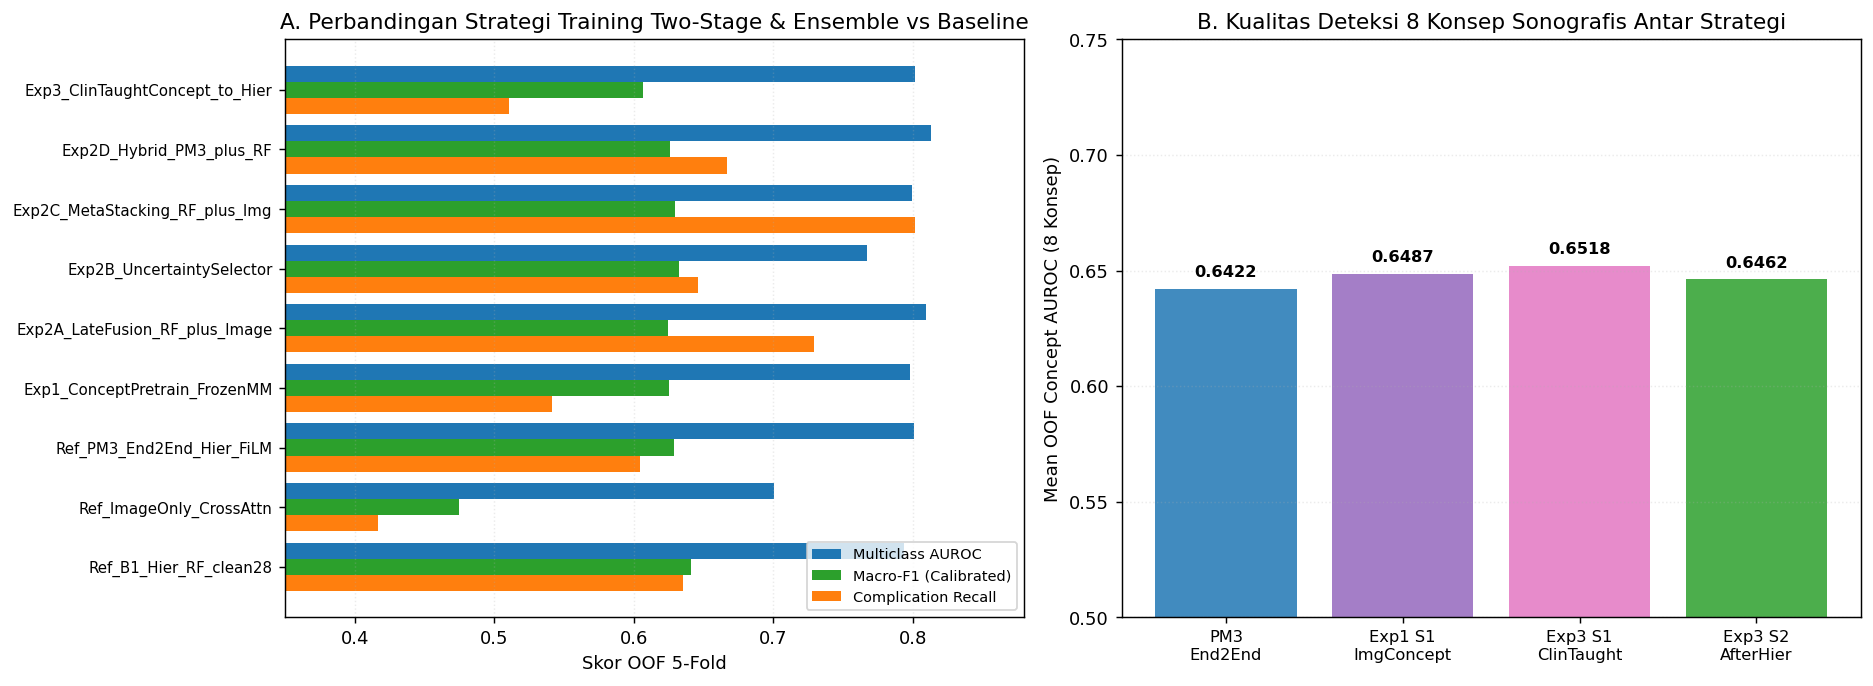

In [5]:
# ==================== PERBANDINGAN MASTER, UJI STATISTIK, BRIER/ECE, & VISUALISASI ====================
def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)
    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob <= bins[i + 1] if i == n_bins - 1 else y_prob < bins[i + 1])
        if mask.sum() > 0:
            ece += (mask.sum() / n) * abs(float(y_true[mask].mean()) - float(y_prob[mask].mean()))
    return float(ece)

def _fast_mf1(y: np.ndarray, pred: np.ndarray) -> float:
    cm = np.bincount(y * 3 + pred, minlength=9).reshape(3, 3)
    tp = np.diag(cm).astype(float)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    denom = 2.0 * tp + fp + fn
    return float(np.divide(2.0 * tp, denom, out=np.zeros_like(tp), where=denom > 0).mean())

def _auc_3c_fast(y: np.ndarray, probs: np.ndarray) -> float:
    aucs = []
    for k in (0, 1, 2):
        yb = (y == k)
        n1, n0 = int(yb.sum()), int((~yb).sum())
        ranks = rankdata(probs[:, k], method="average")
        aucs.append((ranks[yb].sum() - n1 * (n1 + 1) * 0.5) / (n1 * n0))
    return float(np.mean(aucs))

def paired_test(name_a: str, df_a: pd.DataFrame, name_b: str, df_b: pd.DataFrame, n_boot: int = 5000, seed: int = 42) -> dict:
    m = df_a.merge(df_b, on=["patient_id", "label"], suffixes=("_a", "_b"))
    y = m["label"].to_numpy(int)
    pa = m[["p_0_a", "p_1_a", "p_2_a"]].to_numpy(float)
    pb = m[["p_0_b", "p_1_b", "p_2_b"]].to_numpy(float)
    pra = (m["pred_calibrated_a"] if "pred_calibrated_a" in m.columns else m["pred_a"]).to_numpy(int)
    prb = (m["pred_calibrated_b"] if "pred_calibrated_b" in m.columns else m["pred_b"]).to_numpy(int)
    obs_d_auc = _auc_3c_fast(y, pa) - _auc_3c_fast(y, pb)
    obs_d_mf1 = _fast_mf1(y, pra) - _fast_mf1(y, prb)
    ok_a, ok_b = pra == y, prb == y
    b_only, c_only = int(np.sum(ok_a & (~ok_b))), int(np.sum((~ok_a) & ok_b))
    mc_p = float(binomtest(b_only, b_only + c_only, p=0.5).pvalue) if (b_only + c_only) > 0 else 1.0
    rng = np.random.default_rng(seed)
    cls_idx = [np.flatnonzero(y == k) for k in (0, 1, 2)]
    d_aucs, d_mf1s = np.empty(n_boot), np.empty(n_boot)
    for i in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in cls_idx])
        yb = y[idx]
        d_aucs[i] = _auc_3c_fast(yb, pa[idx]) - _auc_3c_fast(yb, pb[idx])
        d_mf1s[i] = _fast_mf1(yb, pra[idx]) - _fast_mf1(yb, prb[idx])
    p_auc = min(1.0, float(2.0 * min(np.mean(d_aucs <= 0.0), np.mean(d_aucs >= 0.0))))
    p_mf1 = min(1.0, float(2.0 * min(np.mean(d_mf1s <= 0.0), np.mean(d_mf1s >= 0.0))))
    return {
        "comparison": f"{name_a} vs {name_b}",
        "delta_auroc": obs_d_auc, "ci95_lo": float(np.percentile(d_aucs, 2.5)), "ci95_hi": float(np.percentile(d_aucs, 97.5)),
        "p_auroc": p_auc, "sig_auroc": bool(p_auc < 0.05),
        "delta_mf1": obs_d_mf1, "p_mf1": p_mf1, "sig_mf1": bool(p_mf1 < 0.05), "mcnemar_p": mc_p,
    }

models_eval = [
    ("Ref_B1_Hier_RF_clean28", RUNS_DIR / "07_advanced_two_stage_and_ensemble" / "exp2_ensemble" / "Ref_B1_Hier_RF_clean28"),
    ("Ref_ImageOnly_CrossAttn", RUNS_DIR / "02_b2_image_only_hierarchical_cross_attn"),
    ("Ref_PM3_End2End_Hier_FiLM", RUNS_DIR / f"02_backbone_{BEST_BACKBONE}"),
    ("Exp1_ConceptPretrain_FrozenMM", exp1_dir),
    ("Exp2A_LateFusion_RF_plus_Image", exp2_dir / "Exp2A_LateFusion_RF_plus_ImageOnly"),
    ("Exp2B_UncertaintySelector", exp2_dir / "Exp2B_UncertaintySelector_RF_vs_Image"),
    ("Exp2C_MetaStacking_RF_plus_Img", exp2_dir / "Exp2C_MetaStacking_RF_plus_ImageOnly"),
    ("Exp2D_Hybrid_PM3_plus_RF", exp2_dir / "Exp2D_Hybrid_PM3_plus_RF"),
    ("Exp3_ClinTaughtConcept_to_Hier", exp3_dir),
]

comp_rows, loaded_oofs = [], {}
for mname, d in models_eval:
    cal_p, oof_p = d / "oof_metrics_calibrated.json", d / "oof_predictions.csv"
    if not (cal_p.exists() and oof_p.exists()):
        continue
    cal = json.loads(cal_p.read_text(encoding="utf-8"))
    dfm = pd.read_csv(oof_p).sort_values("patient_id").reset_index(drop=True)
    if "pred_calibrated" not in dfm.columns:
        dfm["pred_calibrated"] = dfm["pred"]
    loaded_oofs[mname] = dfm
    y = dfm["label"].to_numpy(int)
    probs = dfm[["p_0", "p_1", "p_2"]].to_numpy(float)
    y_oh = np.eye(3)[y]
    mc_brier = float(np.mean(np.sum((probs - y_oh) ** 2, axis=1)))
    comp_ece = compute_ece((y == 2).astype(int), probs[:, 2], 10)
    diag_ece = compute_ece((y > 0).astype(int), 1.0 - probs[:, 0], 10)
    c_auc_mean = float(pd.read_csv(d / "concept_summary.csv")["auroc"].mean()) if (d / "concept_summary.csv").exists() else float("nan")
    comp_rows.append({
        "model": mname,
        "accuracy": float(cal["accuracy"]),
        "macro_f1": float(cal["macro_f1"]),
        "multiclass_auroc": float(cal["multiclass_auroc"]),
        "macro_aupr": float(cal["macro_aupr"]),
        "complication_recall": float(cal["complication_recall"]),
        "mc_brier": mc_brier,
        "diag_ece": diag_ece,
        "comp_ece": comp_ece,
        "concept_mean_auroc": c_auc_mean,
    })

df_comp = pd.DataFrame(comp_rows)
df_comp.to_csv(OUT_DIR / "07_master_comparison.csv", index=False)
print("=== 07_master_comparison.csv ===")
display(df_comp.round(4))

# Uji statistik berpasangan terhadap PM3_End2End dan B1_Hier_RF
stat_list = []
ref_pm3 = loaded_oofs["Ref_PM3_End2End_Hier_FiLM"]
ref_rf = loaded_oofs["Ref_B1_Hier_RF_clean28"]
for mname in [
    "Exp1_ConceptPretrain_FrozenMM", "Exp2A_LateFusion_RF_plus_Image",
    "Exp2B_UncertaintySelector", "Exp2C_MetaStacking_RF_plus_Img",
    "Exp2D_Hybrid_PM3_plus_RF", "Exp3_ClinTaughtConcept_to_Hier"
]:
    if mname in loaded_oofs:
        stat_list.append(paired_test(mname, loaded_oofs[mname], "Ref_PM3_End2End", ref_pm3))
        stat_list.append(paired_test(mname, loaded_oofs[mname], "Ref_B1_Hier_RF", ref_rf))

df_stat7 = pd.DataFrame(stat_list)
df_stat7.to_csv(OUT_DIR / "07_paired_stat_tests.csv", index=False)
print("=== 07_paired_stat_tests.csv ===")
display(df_stat7.round(4))

# Stage-1 vs Stage-2 Concept AUROC Comparison
s1_exp1_c = pd.concat([pd.read_csv(exp1_dir / f"fold_{k}/stage1_concept_metrics.csv") for k in range(1, 6)]).groupby("concept")["auroc"].mean()
s1_exp3_c = pd.concat([pd.read_csv(exp3_dir / f"fold_{k}/stage1_concept_metrics.csv") for k in range(1, 6)]).groupby("concept")["auroc"].mean()
s2_exp3_c = pd.read_csv(exp3_dir / "concept_summary.csv").set_index("concept")["auroc"]
e2e_c = pd.read_csv(RUNS_DIR / f"02_backbone_{BEST_BACKBONE}/concept_summary.csv").set_index("concept")["auroc"]
df_ccomp = pd.DataFrame({
    "PM3_End2End": e2e_c,
    "Exp1_Stage1_ImgConcept": s1_exp1_c,
    "Exp3_Stage1_ClinTaught": s1_exp3_c,
    "Exp3_Stage2_AfterHier": s2_exp3_c,
})
df_ccomp.to_csv(OUT_DIR / "07_concept_stage_comparison.csv")
print("=== 07_concept_stage_comparison.csv (Mean AUROC per Tahap) ===")
print(df_ccomp.mean().round(4))
display(df_ccomp.round(4))

# Plot 2-Panel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.4))
y = np.arange(len(df_comp))
h = 0.27
ax1.barh(y + h, df_comp["multiclass_auroc"], height=h, color="#1f77b4", label="Multiclass AUROC")
ax1.barh(y, df_comp["macro_f1"], height=h, color="#2ca02c", label="Macro-F1 (Calibrated)")
ax1.barh(y - h, df_comp["complication_recall"], height=h, color="#ff7f0e", label="Complication Recall")
ax1.set_yticks(y)
ax1.set_yticklabels(df_comp["model"], fontsize=8.3)
ax1.set_xlim(0.35, 0.88)
ax1.set_xlabel("Skor OOF 5-Fold")
ax1.set_title("A. Perbandingan Strategi Training Two-Stage & Ensemble vs Baseline")
ax1.grid(axis="x", alpha=0.25, ls=":")
ax1.legend(loc="lower right", fontsize=8)

c_means = df_ccomp.mean()
x2 = np.arange(len(c_means))
bars = ax2.bar(x2, c_means.values, color=["#1f77b4", "#9467bd", "#e377c2", "#2ca02c"], alpha=0.85)
for b_bar, v in zip(bars, c_means.values):
    ax2.text(b_bar.get_x() + b_bar.get_width() / 2, v + 0.004, f"{v:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(["PM3\nEnd2End", "Exp1 S1\nImgConcept", "Exp3 S1\nClinTaught", "Exp3 S2\nAfterHier"], fontsize=9)
ax2.set_ylim(0.50, max(0.75, float(c_means.max()) + 0.04))
ax2.set_ylabel("Mean OOF Concept AUROC (8 Konsep)")
ax2.set_title("B. Kualitas Deteksi 8 Konsep Sonografis Antar Strategi")
ax2.grid(axis="y", alpha=0.25, ls=":")

fig.tight_layout()
fig.savefig(OUT_DIR / "07_advanced_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Laporan teks ringkas
rep_lines = [
    "============================================================================",
    "RINGKASAN EKSPERIMEN LANJUTAN 07 (TWO-STAGE CONCEPT & ENSEMBLE, 5-FOLD OOF)",
    "============================================================================",
    "",
    "[1] MASTER METRIK",
]
for _, r in df_comp.iterrows():
    rep_lines.append(
        f"  - {r['model']:32s} | Acc={r['accuracy']:.4f} MF1={r['macro_f1']:.4f} AUROC={r['multiclass_auroc']:.4f} "
        f"AUPR={r['macro_aupr']:.4f} CompRec={r['complication_recall']:.4f} | Brier={r['mc_brier']:.4f} CompECE={r['comp_ece']:.4f}"
    )
rep_lines += ["", "[2] UJI STATISTIK BERPASANGAN (B=5000)"]
for _, r in df_stat7.iterrows():
    rep_lines.append(
        f"  - {r['comparison']:52s} | dAUROC={r['delta_auroc']:+.4f} [{r['ci95_lo']:+.4f},{r['ci95_hi']:+.4f}] p={r['p_auroc']:.4f} | "
        f"dMF1={r['delta_mf1']:+.4f} p={r['p_mf1']:.4f} | McNemar p={r['mcnemar_p']:.4f}"
    )
rep_lines += ["", "[3] MEAN CONCEPT AUROC PER TAHAP"]
for k_c, v_c in c_means.items():
    rep_lines.append(f"  - {k_c:26s}: {v_c:.4f}")

rep_txt = "\n".join(rep_lines)
(OUT_DIR / "07_advanced_report.txt").write_text(rep_txt, encoding="utf-8")
print(rep_txt)
